In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import rearrangement_algorithm as ra
from library.generate_marginals import CapacityMarginal

%matplotlib inline

In [2]:
seed = 0; d = 50
rng = np.random.default_rng(seed)
mu = rng.normal(loc = 10, scale = 4, size = d)
sd = rng.uniform(0.5, 5, size = d)
ms = [CapacityMarginal(mu[i], sd[i], asset_type = 'ordinary') for i in range(d)]
qf = [m.ppf for m in ms]

In [3]:
copula = 'comonotonic'  # 'independent', 'gaussian', 'comonotonic'
rho = 0.5; m = 100_000
rng = np.random.default_rng(seed + 1)

# Joint initial-energy draws; each trajectory depletes one draw over time.
if copula == 'independent':
    u = rng.random((m, d))
elif copula == 'gaussian':
    if not (-1 / (d - 1) if d > 1 else -1) <= rho <= 1:
        raise ValueError('Invalid equicorrelation')
    corr = (1 - rho) * np.eye(d) + rho * np.ones((d, d))
    u = stats.norm.cdf(rng.multivariate_normal(np.zeros(d), corr, size = m))
elif copula == 'comonotonic':
    u = np.repeat(rng.random((m, 1)), d, axis = 1)
else:
    raise ValueError('Unknown copula')

x = np.column_stack([ms[i].ppf(u[:, i]) for i in range(d)])
gt = dict(copula = copula, rho = rho if copula == 'gaussian' else None,
          x = x, z = x.sum(axis = 1))

In [4]:
# Policies receive the marginals, not gt or future realizations.
info = dict(marginals = ms)
# Policies use cumulative delivery and depletion observations; they do not receive gt.

In [5]:
alphas = np.arange(80, 100) / 100; steps = 10_000
rows = []
for alpha in alphas:
    eps = 1 - alpha
    l, u = ra.bounds_VaR(eps, qf, method = 'lower', num_steps = steps, abstol = 1e-8)
    lo0, lo1 = float(l[0]), float(u[0])
    l, u = ra.bounds_VaR(eps, qf, method = 'upper', num_steps = steps, abstol = 1e-8)
    hi0, hi1 = float(l[0]), float(u[0])
    rows.append([alpha, lo0, lo1, hi0, hi1])

out = pd.DataFrame(rows, columns = ['alpha', 'vmin_lo', 'vmin_hi', 'vmax_lo', 'vmax_hi'])
# Both dependence extrema have their own RA numerical bracket.
out['gap'] = (out.vmax_lo + out.vmax_hi - out.vmin_lo - out.vmin_hi) / 2

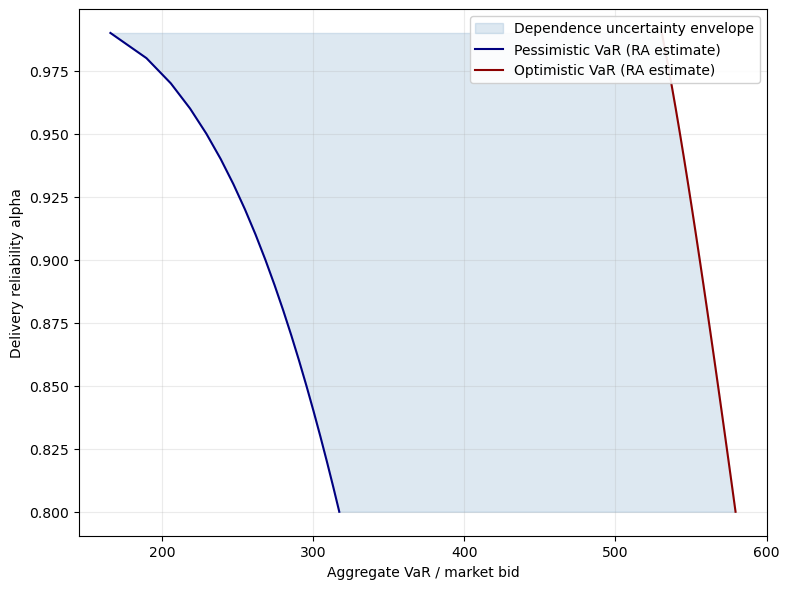

In [6]:
# Midpoints summarize RA brackets; they are numerical estimates of the extrema.
vmin = (out.vmin_lo + out.vmin_hi) / 2
vmax = (out.vmax_lo + out.vmax_hi) / 2
fig, ax = plt.subplots(figsize = (8, 6))
ax.fill_betweenx(out.alpha, vmin, vmax, color = 'steelblue', alpha = 0.18, label = 'Dependence uncertainty envelope')
ax.plot(vmin, out.alpha, color = 'navy', label = 'Pessimistic VaR (RA estimate)')
ax.plot(vmax, out.alpha, color = 'darkred', label = 'Optimistic VaR (RA estimate)')
# ax.fill_betweenx(out.alpha, out.vmin_lo, out.vmin_hi, color = 'orange', alpha = 0.7, label = 'RA numerical brackets')
# ax.fill_betweenx(out.alpha, out.vmax_lo, out.vmax_hi, color = 'orange', alpha = 0.7)
ax.set(xlabel = 'Aggregate VaR / market bid', ylabel = 'Delivery reliability alpha')
ax.grid(alpha = 0.25); ax.legend(loc = 'upper right', framealpha = 0.9)
plt.tight_layout(); plt.show()

In [7]:
def greedy(delivered, alive, t, b, info):
    mu = info['mu']; sd = info['sd']
    z = (delivered - mu) / sd
    s = mu + sd * np.exp(stats.norm.logpdf(z) - stats.norm.logsf(z)) - delivered
    s = np.where(delivered == 0, info['mean'], s)
    s[~alive] = -np.inf
    return np.argsort(-s)[:min(info['k'], int(alive.sum()))]

In [8]:
def proportional(delivered, alive, t, b, info):
    need = max(0., b - delivered.sum()) / (info['n'] - t)
    k = min(info['k'], int(np.ceil(need / info['de'])), int(alive.sum()))
    mu = info['mu']; sd = info['sd']
    z = (delivered - mu) / sd
    s = mu + sd * np.exp(stats.norm.logpdf(z) - stats.norm.logsf(z)) - delivered
    s = np.where(delivered == 0, info['mean'], s)
    s[~alive] = -np.inf
    return np.argsort(-s)[:k]

In [9]:
def step(e, ids, remaining, de):
    y = np.zeros(len(e)); dry = np.zeros(len(e), dtype = bool)
    for i in ids:
        if remaining <= 0: break
        ask = min(de, remaining)
        y[i] = min(ask, e[i])
        e[i] -= y[i]; remaining -= y[i]
        dry[i] = y[i] < ask - 1e-9  # partial delivery reveals depletion
    return e, y, dry

In [10]:
n = 4; dt = 15 / 60; rate = 10.; k = d; ns = 500; tol = 1e-9
de = rate * dt
bs = np.linspace(float(vmin.min()), float(vmax.max()), 41)
policies = {'greedy': greedy, 'greedy-proportional': proportional}

if ns > len(gt['x']): raise ValueError('Generate at least ns ground-truth draws')
if any(m.asset_type != 'ordinary' for m in ms):
    raise ValueError('These belief updates require the ordinary censored Gaussian marginals')

# Initial X is stored energy; rate*dt is the maximum delivery per asset per step.
info.update(mu = mu.copy(), sd = sd.copy(), n = n, k = k, de = de,
            mean = mu * stats.norm.cdf(mu / sd) + sd * stats.norm.pdf(mu / sd))
e0 = gt['x'][:ns].copy()  # same hidden initial draws for every bid and policy

In [11]:
total = np.zeros((len(policies), len(bs), ns))
for j, b in enumerate(bs):
    for p, pick in enumerate(policies.values()):
        for r in range(ns):
            e = e0[r].copy(); delivered = np.zeros(d); alive = np.ones(d, dtype = bool)
            for t in range(n):
                remaining = b - delivered.sum()
                if remaining <= tol or not alive.any(): break
                ids = pick(delivered, alive, t, b, info)
                e, y, dry = step(e, ids, remaining, de)
                delivered += y; alive[dry] = False
            total[p, j, r] = delivered.sum()

In [12]:
freq = (total >= bs[None, :, None] - tol).mean(axis = 2)
perf = pd.DataFrame([(name, b, freq[p, j])
                     for p, name in enumerate(policies) for j, b in enumerate(bs)],
                    columns = ['policy', 'bid', 'completion_probability'])

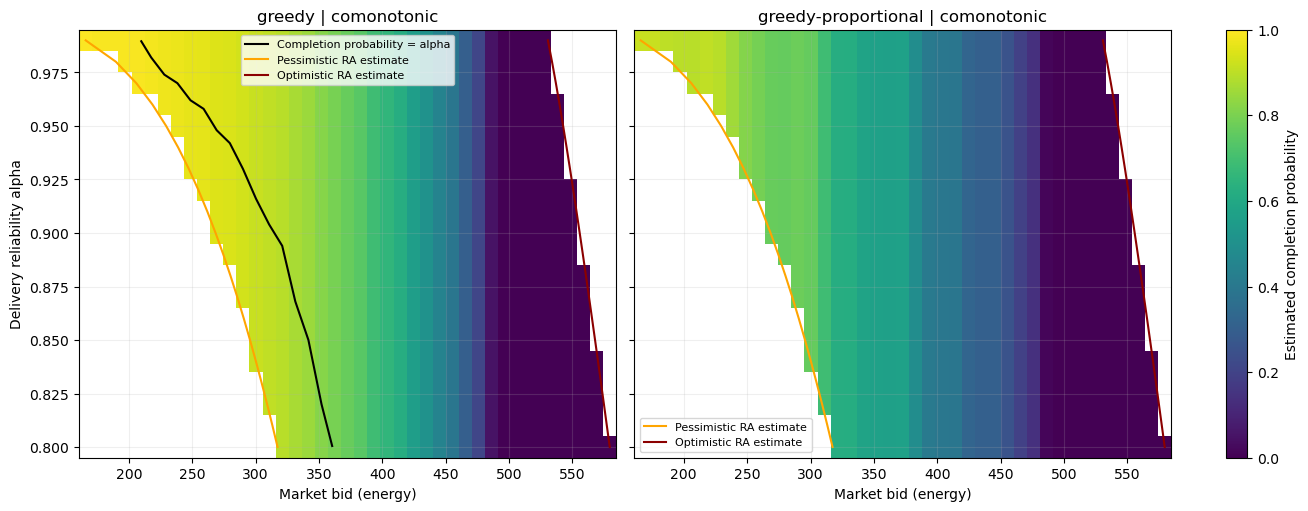

In [13]:
# Alpha is the reliability target; these policies use the bid, not alpha.
# The RA envelope concerns stored energy; policies also face rate and dispatch limits.
inside = (bs[None, :] >= np.asarray(vmin)[:, None]) & (bs[None, :] <= np.asarray(vmax)[:, None])
fig, axs = plt.subplots(1, 2, figsize = (13, 5), sharex = True, sharey = True, layout = 'constrained')
for p, (ax, name) in enumerate(zip(axs, policies)):
    z = np.ma.masked_where(~inside, np.broadcast_to(freq[p], inside.shape))
    im = ax.pcolormesh(bs, alphas, z, shading = 'nearest', cmap = 'viridis', vmin = 0, vmax = 1)
    margin = z - alphas[:, None]
    if margin.min() < 0 < margin.max():
        ax.contour(bs, alphas, margin, levels = [0], colors = 'black', linewidths = 1.5)
        ax.plot([], [], color = 'black', label = 'Completion probability = alpha')  # legend handle only
    ax.plot(vmin, alphas, color = 'orange', label = 'Pessimistic RA estimate')
    ax.plot(vmax, alphas, color = 'darkred', label = 'Optimistic RA estimate')
    ax.set(xlabel = 'Market bid (energy)', title = f'{name} | {copula}')
    ax.legend(fontsize = 8); ax.grid(alpha = 0.2)
axs[0].set_ylabel('Delivery reliability alpha')
fig.colorbar(im, ax = axs, label = 'Estimated completion probability')
plt.show()

In [14]:
def plot_run(pick, b, e0, info, dt):
    n = info['n']; k = info['k']; de = info['de']; d = len(e0)
    e = e0.copy(); delivered = np.zeros(d); alive = np.ones(d, dtype = bool)
    log = np.zeros((n, d)); live = np.zeros(n + 1, dtype = int); live[0] = d
    for t in range(n):
        if b - delivered.sum() > 1e-9 and alive.any():
            ids = pick(delivered, alive, t, b, info)
            e, y, dry = step(e, ids, b - delivered.sum(), de)
            delivered += y; alive[dry] = False; log[t] = y
        live[t + 1] = alive.sum()

    th = np.arange(n + 1) * dt; pace = b * np.arange(n + 1) / n
    cum = np.r_[0., log.sum(axis = 1).cumsum()]
    left = np.vstack([e0, e0 - log.cumsum(axis = 0)])
    met = bool(cum[-1] >= b - 1e-9)
    fig, axs = plt.subplots(2, 3, figsize = (15, 7), layout = 'constrained')
    ax = axs.ravel()
    fig.suptitle(f'{pick.__name__}: bid = {b:.2f}, delivered = {cum[-1]:.2f}, '
                 f'met = {met}, horizon = {n * dt:g} h')

    ax[0].bar(th[1:], (log > 1e-9).sum(axis = 1), width = dt * 0.6)
    ax[0].axhline(k, color = 'black', linestyle = '--', label = 'Dispatch limit')
    ax[0].set(title = 'Assets delivering per step', ylabel = 'Assets')
    ax[0].legend()

    ax[1].step(th, (left > 1e-9).sum(axis = 1), where = 'post', label = 'True energy > 0')
    ax[1].step(th, live, where = 'post', linestyle = '--', label = 'Not observed depleted')
    ax[1].set(title = 'Remaining availability', ylabel = 'Assets')
    ax[1].legend()

    ax[2].plot(th, pace, 'k--', label = 'Linear reference pace')
    ax[2].step(th, cum, where = 'post', label = 'Actual delivery')
    ax[2].axhline(b, color = 'red', linestyle = ':', label = 'Total bid')
    ax[2].set(title = 'Cumulative delivery', ylabel = 'Energy')
    ax[2].legend()

    ax[3].bar(np.arange(d), (log > 1e-9).sum(axis = 0))
    ax[3].axhline(n, color = 'black', linestyle = '--')
    ax[3].set(title = 'Delivery steps per asset', xlabel = 'Asset', ylabel = 'Steps')

    ax[4].bar(np.arange(d), e0, alpha = 0.4, label = 'Initial energy')
    ax[4].bar(np.arange(d), e, label = 'Remaining energy')
    ax[4].set(title = 'Initial and final energy', xlabel = 'Asset', ylabel = 'Energy')
    ax[4].legend()

    ax[5].bar(th[1:], log.sum(axis = 1), width = dt * 0.6, label = 'Delivered')
    ax[5].axhline(b / n, color = 'red', linestyle = ':', label = 'Evenly paced requirement')
    ax[5].axhline(k * de, color = 'black', linestyle = '--', label = 'Per-step dispatch cap')
    ax[5].set(title = 'Energy delivered per step', ylabel = 'Energy')
    ax[5].legend()
    for j in (0, 1, 2, 5):
        ax[j].set(xlabel = 'Hours', xlim = (0, n * dt + dt * 0.4), xticks = th)
    for a in ax: a.grid(alpha = 0.2)
    plt.show()
    return dict(log = log, remaining = e, delivered = float(cum[-1]), met = met)

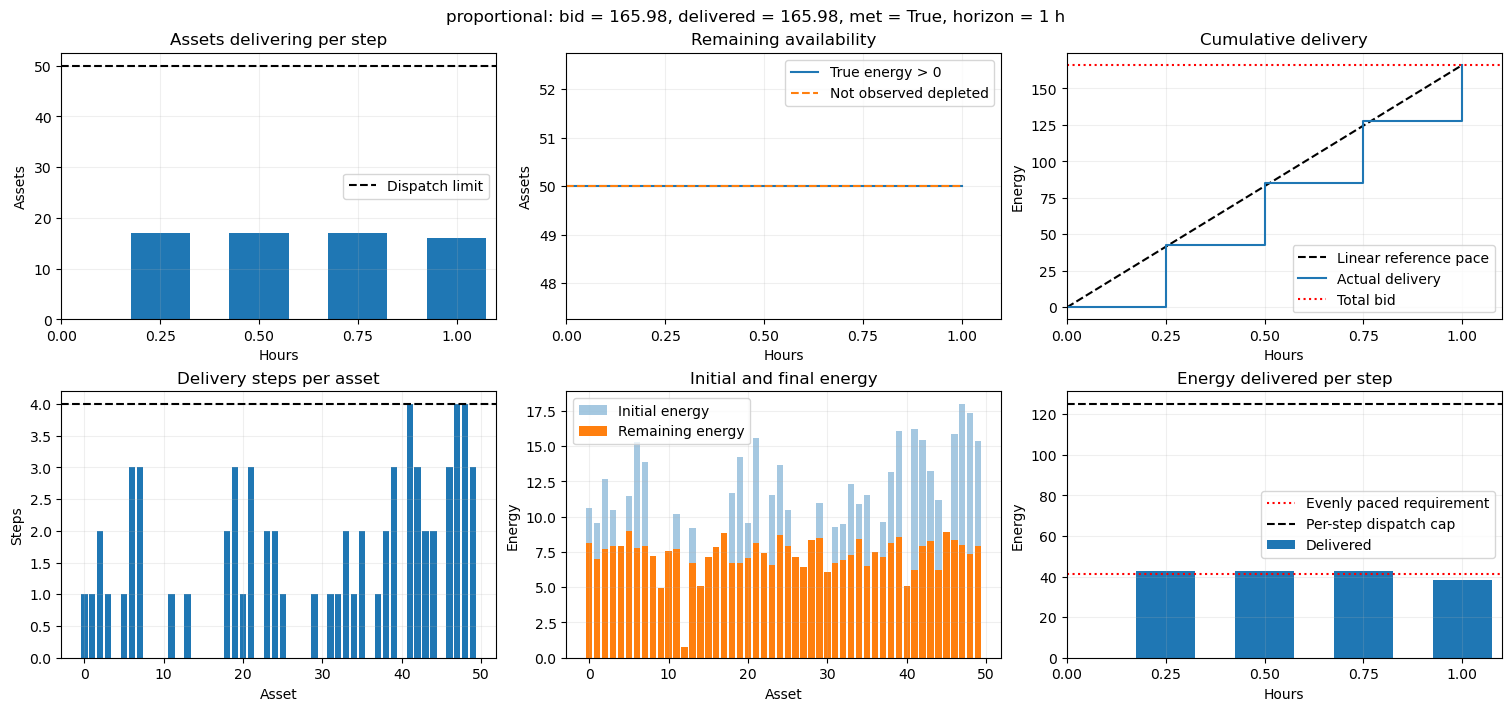

In [15]:
r = 0; b = float(bs[0])
trace = plot_run(proportional, b, e0[r], info, dt)